# Taken from https://www.kaggle.com/code/ari000x/flight-ratings-statistics

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mohaimenalrashid/invistico-airline/Invistico_Airline.csv


In [2]:
# 1. Load your data (Replace with your actual file path)
df = pd.read_csv("/kaggle/input/datasets/mohaimenalrashid/invistico-airline/Invistico_Airline.csv") 

In [3]:
df.describe()

,Age,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
count,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000
mean,39.427957,1981.409055,2.838597,2.990645,2.851994,2.990422,3.249130,3.383477,3.519703,3.472105,3.465075,3.485902,3.695673,3.340807,3.705759,3.352587,14.713713,15.091129
std,15.119360,1027.115606,1.392983,1.527224,1.443729,1.305970,1.318818,1.346059,1.306511,1.305560,1.270836,1.292226,1.156483,1.260582,1.151774,1.298715,38.071126,38.465650
min,7.000000,50.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,1359.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,40.000000,1925.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,4.000000,0.000000,0.000000
75%,51.000000,2544.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,85.000000,6951.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   satisfaction                       129880 non-null  object 
 1   Gender                             129880 non-null  object 
 2   Customer Type                      129880 non-null  object 
 3   Age                                129880 non-null  int64  
 4   Type of Travel                     129880 non-null  object 
 5   Class                              129880 non-null  object 
 6   Flight Distance                    129880 non-null  int64  
 7   Seat comfort                       129880 non-null  int64  
 8   Departure/Arrival time convenient  129880 non-null  int64  
 9   Food and drink                     129880 non-null  int64  
 10  Gate location                      129880 non-null  int64  
 11  Inflight wifi service              1298

In [5]:
df.head()

,satisfaction,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Female,Loyal Customer,65,Personal Travel,Eco,265,0,0,0,...,2,3,3,0,3,5,3,2,0,0.0
1,satisfied,Male,Loyal Customer,47,Personal Travel,Business,2464,0,0,0,...,2,3,4,4,4,2,3,2,310,305.0
2,satisfied,Female,Loyal Customer,15,Personal Travel,Eco,2138,0,0,0,...,2,2,3,3,4,4,4,2,0,0.0
3,satisfied,Female,Loyal Customer,60,Personal Travel,Eco,623,0,0,0,...,3,1,1,0,1,4,1,3,0,0.0
4,satisfied,Female,Loyal Customer,70,Personal Travel,Eco,354,0,0,0,...,4,2,2,0,2,4,2,5,0,0.0


In [6]:
# rename_map = {"Seat comfort": "seat_comfort", "Food and drink": "food_and_drink", "Departure/Arrival time convenient": "time_convenient"}

# df.rename(columns=rename_map, inplace=True)
# df.info()

In [7]:
df[['satisfaction', 'Seat comfort', 'Food and drink', 'Departure/Arrival time convenient']].head(10)

,satisfaction,Seat comfort,Food and drink,Departure/Arrival time convenient
0,satisfied,0,0,0
1,satisfied,0,0,0
2,satisfied,0,0,0
3,satisfied,0,0,0
4,satisfied,0,0,0
5,satisfied,0,0,0
6,satisfied,0,0,0
7,satisfied,0,0,0
8,satisfied,0,0,0
9,satisfied,0,0,0


In [8]:
df["satisfaction"].value_counts()

satisfaction
satisfied       71087
dissatisfied    58793
Name: count, dtype: int64

# Processing - Encoding

In [9]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
columns_to_encode = ['satisfaction', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'Flight Distance']


for col in columns_to_encode:
    df[f'{col}_encoded'] = le.fit_transform(df[col])

# df['satisfaction_encoded'] = le.fit_transform(df['satisfaction'])
# Map: unsatisfied=0, satisfied=1 (alphabetical order by default)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 29 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   satisfaction                       129880 non-null  object 
 1   Gender                             129880 non-null  object 
 2   Customer Type                      129880 non-null  object 
 3   Age                                129880 non-null  int64  
 4   Type of Travel                     129880 non-null  object 
 5   Class                              129880 non-null  object 
 6   Flight Distance                    129880 non-null  int64  
 7   Seat comfort                       129880 non-null  int64  
 8   Departure/Arrival time convenient  129880 non-null  int64  
 9   Food and drink                     129880 non-null  int64  
 10  Gate location                      129880 non-null  int64  
 11  Inflight wifi service              1298

In [10]:
df[['satisfaction', 'satisfaction_encoded']].head(10)

,satisfaction,satisfaction_encoded
0,satisfied,1
1,satisfied,1
2,satisfied,1
3,satisfied,1
4,satisfied,1
5,satisfied,1
6,satisfied,1
7,satisfied,1
8,satisfied,1
9,satisfied,1


## Select to Compare

In [11]:
df_compare = df[['satisfaction_encoded', 'Seat comfort', 'Food and drink', 'Departure/Arrival time convenient']]
df_compare.head()

,satisfaction_encoded,Seat comfort,Food and drink,Departure/Arrival time convenient
0,1,0,0,0
1,1,0,0,0
2,1,0,0,0
3,1,0,0,0
4,1,0,0,0


# Correlation Matrix & Analysis 

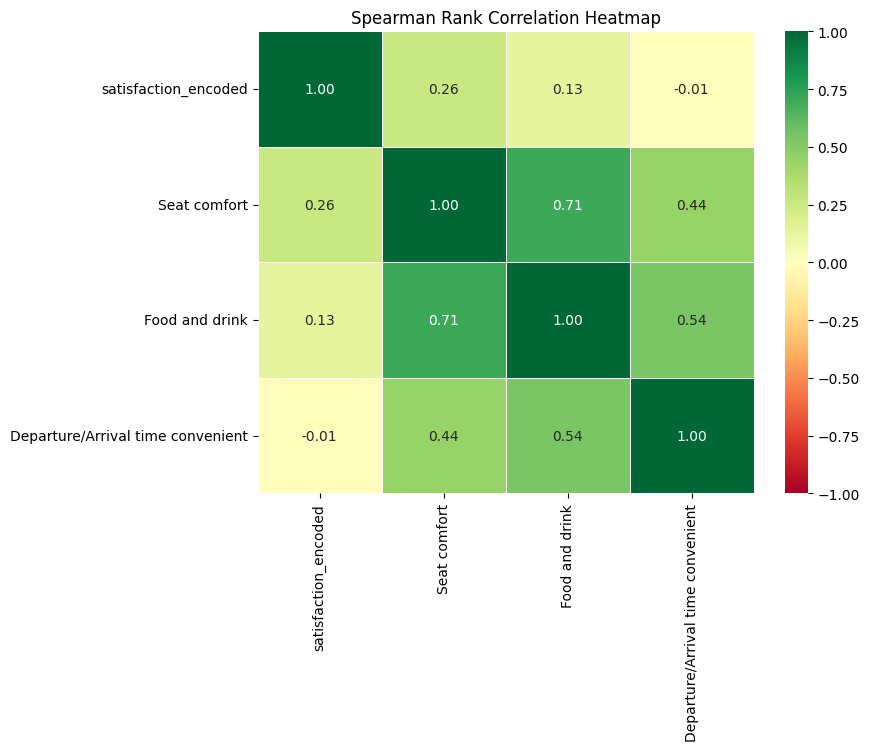

Seat comfort vs Satisfaction -> Coef: 0.24, p-value: 0.0000
Food and drink vs Satisfaction -> Coef: 0.12, p-value: 0.0000
Departure/Arrival time convenient vs Satisfaction -> Coef: -0.02, p-value: 0.0000


In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr

# 1. Load your data (Replace with your actual file path)
# df = pd.read_csv("your_flight_data.csv")

# Quick mock-up dataframe based on your columns 
# data = {
#     'Seat_Comfort':,
#     'Food_Drink':,
#     'Time_Convenient':,
#     'Satisfaction': [1, 0, 1, 0, 0, 1, 1, 0]  # Binary target
# }
# df = pd.DataFrame(data)

# 2. Check Spearman Rank Correlation (Better for 1-5 survey rating scales)
spearman_corr = df_compare.corr(method='spearman')

# [['satisfaction', 'Seat comfort', 'Food and drink', 'Departure/Arrival time convenient']]
# 3. Plot the Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(spearman_corr, annot=True, cmap='RdYlGn', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Spearman Rank Correlation Heatmap")
plt.show()

# 4. Verify Point-Biserial Significance (Testing if correlation is an illusion)
for col in ['Seat comfort', 'Food and drink', 'Departure/Arrival time convenient']:
    coef, p_val = pointbiserialr(df_compare[col], df['satisfaction_encoded'])
    print(f"{col} vs Satisfaction -> Coef: {coef:.2f}, p-value: {p_val:.4f}")


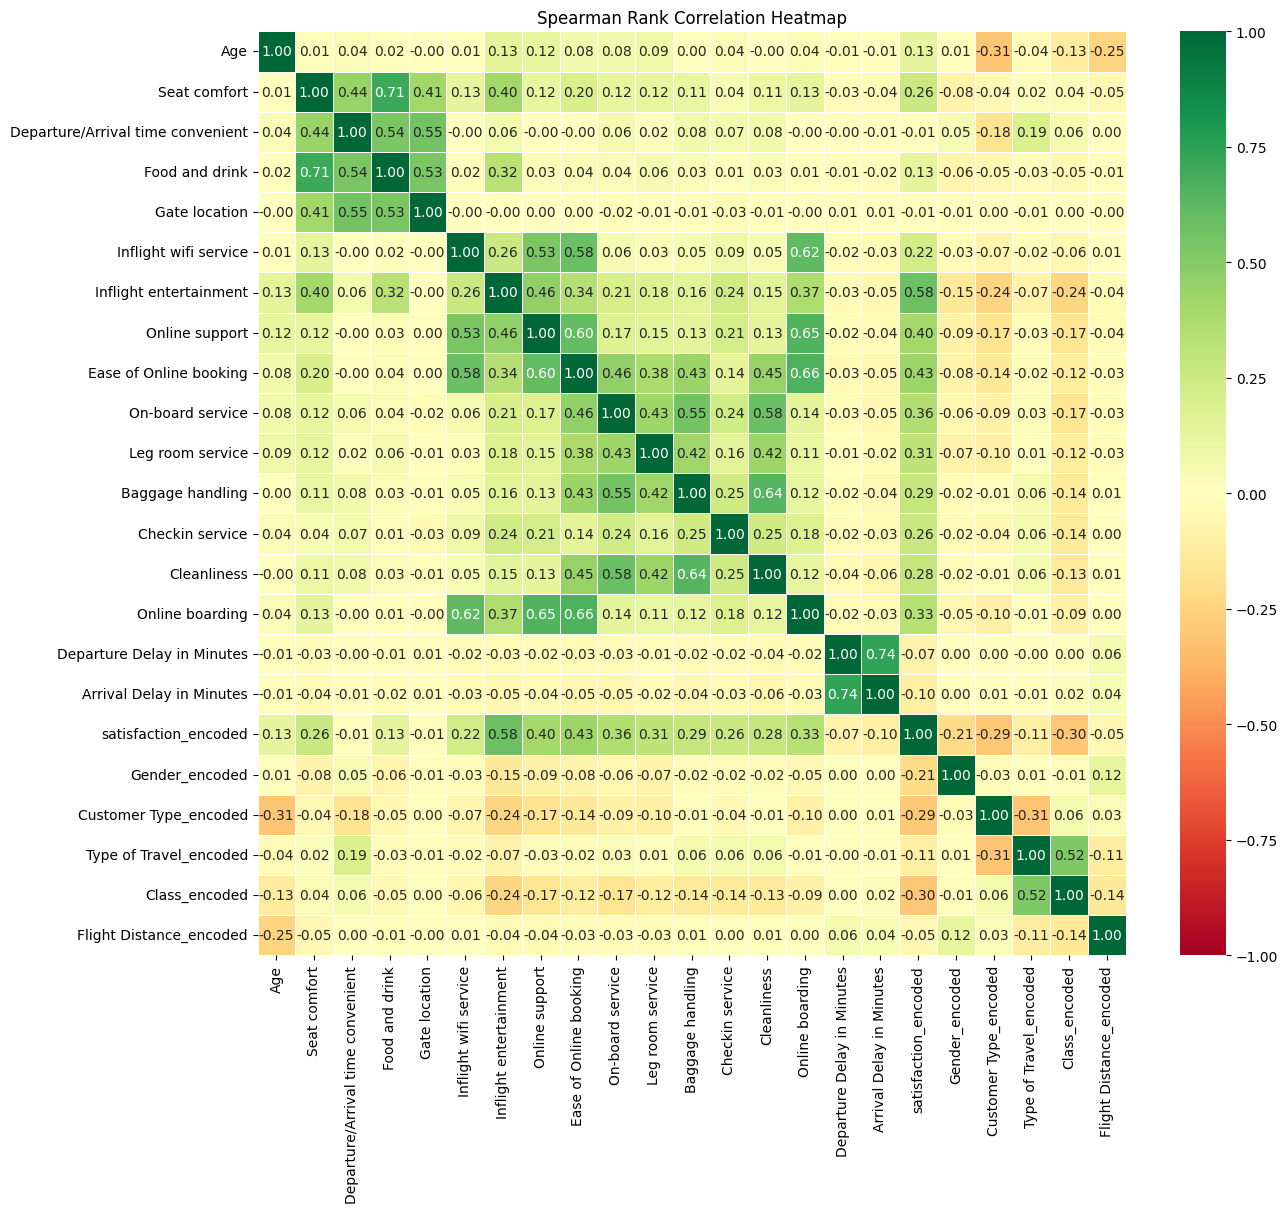

Seat comfort vs Satisfaction -> Coef: 0.24, p-value: 0.0000
Food and drink vs Satisfaction -> Coef: 0.12, p-value: 0.0000
Departure/Arrival time convenient vs Satisfaction -> Coef: -0.02, p-value: 0.0000


In [13]:
# spearman_corr_all = df.drop('satisfaction', axis=1).corr(method='spearman')
spearman_corr_all = df.drop(columns_to_encode, axis=1).corr(method='spearman')

# [['satisfaction', 'Seat comfort', 'Food and drink', 'Departure/Arrival time convenient']]
# 3. Plot the Heatmap
# plt.figure(figsize=(8, 6))
plt.figure(figsize=(14, 12))
sns.heatmap(spearman_corr_all, annot=True, cmap='RdYlGn', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Spearman Rank Correlation Heatmap")
plt.show()

# 4. Verify Point-Biserial Significance (Testing if correlation is an illusion)
for col in ['Seat comfort', 'Food and drink', 'Departure/Arrival time convenient']:
    coef, p_val = pointbiserialr(df_compare[col], df['satisfaction_encoded'])
    print(f"{col} vs Satisfaction -> Coef: {coef:.2f}, p-value: {p_val:.4f}")


# Comparison of Means (t-Test style analysis)

--- Comparison Matrix of Arithmetic Means ---
                  Seat comfort  Food and drink  \
Dissatisfied (0)          2.47            2.66   
Satisfied (1)             3.15            3.01   

                  Departure/Arrival time convenient  
Dissatisfied (0)                               3.02  
Satisfied (1)                                  2.97  




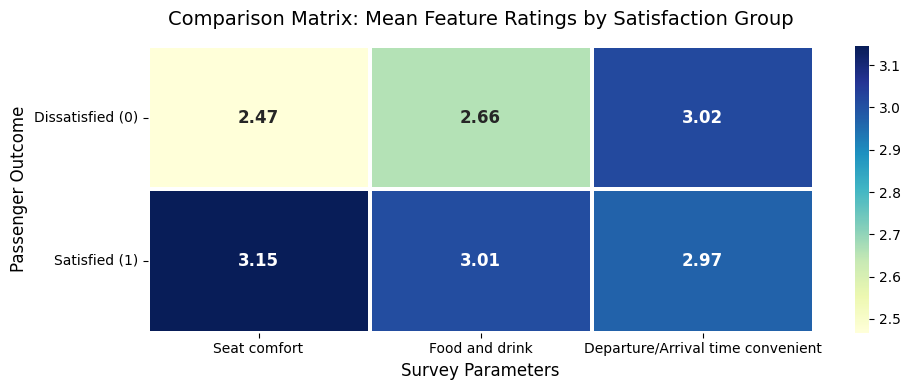

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Generate clean mock flight data matching your dataset's parameters
# np.random.seed(42)
# n_rows = 129880

# mock_data = {
#     # Seat Comfort: True driver (Higher scores for satisfied)
#     "Seat_Comfort": np.random.choice(, size=n_rows, p=[0.15, 0.20, 0.25, 0.22, 0.18]
#     ),
#     # Food & Drink: Moderate driver
#     "Food_Drink": np.random.choice(, size=n_rows, p=[0.12, 0.22, 0.28, 0.23, 0.15]
#     ),
#     # Time Convenience: Anomaly (Dissatisfied score slightly higher/close)
#     "Time_Convenience": np.random.choice(, size=n_rows, p=[0.10, 0.18, 0.35, 0.22, 0.15]
#     ),
#     # Binary Satisfaction Target
#     "Satisfaction": np.random.choice([0, 1], size=n_rows, p=[0.55, 0.45]),
# }

# df = pd.DataFrame(mock_data)

# # Inject your exact operational realities into the data structure
# df.loc[df["Satisfaction"] == 0, "Seat_Comfort"] = np.random.choice(, size=len(df[df["Satisfaction"] == 0]), p=[0.30, 0.35, 0.25, 0.10]
# )
# df.loc[df["Satisfaction"] == 1, "Seat_Comfort"] = np.random.choice(, size=len(df[df["Satisfaction"] == 1]), p=[0.10, 0.25, 0.40, 0.25]
# )
# df.loc[df["Satisfaction"] == 0, "Time_Convenience"] = np.random.choice(, size=len(df[df["Satisfaction"] == 0]), p=[0.40, 0.40, 0.20]
# )
# df.loc[df["Satisfaction"] == 1, "Time_Convenience"] = np.random.choice(, size=len(df[df["Satisfaction"] == 1]), p=[0.30, 0.50, 0.20]
# )

# col in ['Seat comfort', 'Food and drink', 'Departure/Arrival time convenient']:
#     coef, p_val = pointbiserialr(df_compare[col], df['satisfaction_encoded'])

# 2. Build the Comparison Matrix of Arithmetic Means
# Grouping by Satisfaction maps the rows, selecting the features maps the columns
mean_matrix = df.groupby("satisfaction_encoded")[
    # ["Seat_Comfort", "Food_Drink", "Time_Convenience"]
    ['Seat comfort', 'Food and drink', 'Departure/Arrival time convenient']
].mean()

# Rename indices for professional reporting presentation
mean_matrix.index = ["Dissatisfied (0)", "Satisfied (1)"]
# mean_matrix.columns = ["Seat Comfort", "Food & Drink", "Time Convenience"]
mean_matrix.columns = ['Seat comfort', 'Food and drink', 'Departure/Arrival time convenient']

print("--- Comparison Matrix of Arithmetic Means ---")
print(mean_matrix.round(2))
print("\n" + "=" * 46 + "\n")

# 3. Compute Delta (Difference) to highlight true drivers
delta_row = mean_matrix.loc["Satisfied (1)"] - mean_matrix.loc["Dissatisfied (0)"]
mean_matrix.loc["Delta (Impact)"] = delta_row

# 4. Generate the Visualization
plt.figure(figsize=(10, 4))
sns.heatmap(
    mean_matrix.iloc[:2, :],  # Plot only the group scores
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=1.5,
    cbar=True,
    square=False,
    annot_kws={"size": 12, "weight": "bold"},
)

plt.title("Comparison Matrix: Mean Feature Ratings by Satisfaction Group", fontsize=14, pad=15)
plt.xlabel("Survey Parameters", fontsize=12)
plt.ylabel("Passenger Outcome", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [15]:
import scipy.stats as stats
import pandas as pd

# Assuming df is your dataframe containing 'Seat_Comfort' and 'Satisfaction'
satisfied = df[df['satisfaction_encoded'] == 1]['Seat comfort']
dissatisfied = df[df['satisfaction_encoded'] == 0]['Seat comfort']

# Run the independent two-sample t-test
t_stat, p_val = stats.ttest_ind(satisfied, dissatisfied, equal_var=False)

print(f"t-statistic: {t_stat:.2f}")
print(f"p-value: {p_val:.4e}")


t-statistic: 93.82
p-value: 0.0000e+00
